Anas Alhamzi - 2240003869

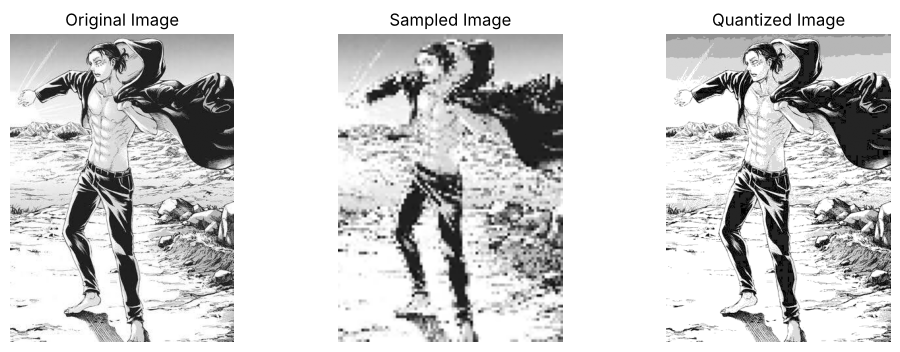

In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

def sample_image(image, factor):
    height, width = image.shape[:2]
    sampled_image = cv2.resize(image, (width // factor, height // factor), interpolation=cv2.INTER_NEAREST)
    return sampled_image

def quantize_image(image, levels):
    quantized_image = np.floor(image / (256 // levels)) * (256 // levels)
    quantized_image = quantized_image.astype(np.uint8)
    return quantized_image

def plot_images(original, sampled, quantized):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(original, cmap='gray')
    plt.title('Original Image')
    plt.axis('off')
    plt.subplot(1, 3, 2)
    plt.imshow(sampled, cmap='gray')
    plt.title('Sampled Image')
    plt.axis('off')
    plt.subplot(1, 3, 3)
    plt.imshow(quantized, cmap='gray')
    plt.title('Quantized Image')
    plt.axis('off')
    plt.show()

image_path = 'input.png'
if not os.path.exists(image_path):
    image_path = 'images/input.png'

original_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
if original_image is None:
    raise FileNotFoundError(f"Could not load image at '{image_path}'. Put input.png next to this notebook.")

sampling_factor = 4
quantization_levels = 8

sampled_image = sample_image(original_image, sampling_factor)
quantized_image = quantize_image(original_image, quantization_levels)

plot_images(original_image, sampled_image, quantized_image)

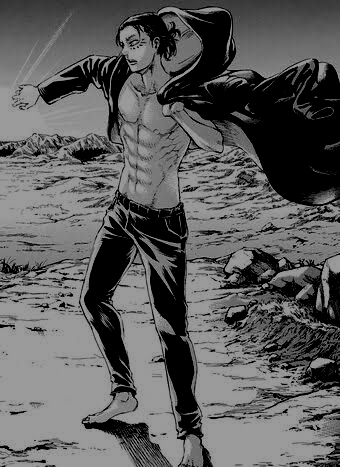

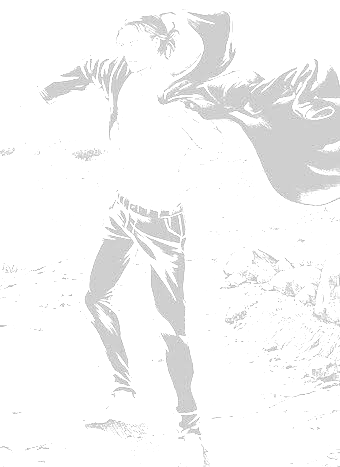

In [2]:
from PIL import Image
from IPython.display import display
import numpy as np
import cv2

im1arr = cv2.imread('input.png', cv2.IMREAD_GRAYSCALE)
im2arr = np.full_like(im1arr, 100)

subtraction = cv2.subtract(im1arr, im2arr)
display(Image.fromarray(subtraction))

added_constant = cv2.add(im1arr, 175)
display(Image.fromarray(added_constant))


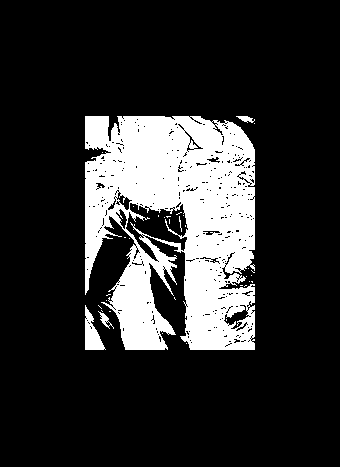

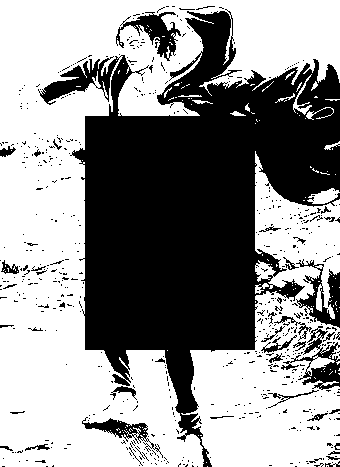

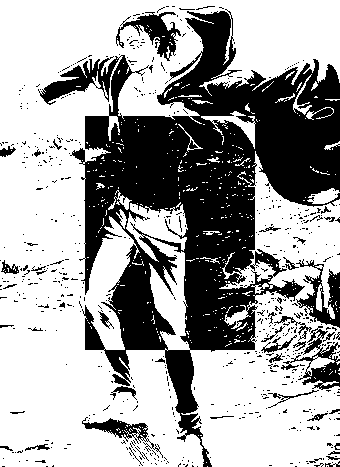

In [3]:
import numpy as np
import cv2
from PIL import Image
from IPython.display import display

gray = cv2.imread('input.png', cv2.IMREAD_GRAYSCALE)
_, arr1 = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

arr2 = np.zeros_like(arr1)
h, w = arr1.shape
arr2[h // 4: 3 * h // 4, w // 4: 3 * w // 4] = 255

intersection = cv2.bitwise_and(arr1, arr2)
display(Image.fromarray(intersection))

set_diff = cv2.subtract(arr1, arr2)
display(Image.fromarray(set_diff))

sym_diff = cv2.bitwise_xor(arr1, arr2)
display(Image.fromarray(sym_diff))
